In [1]:
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter

In [2]:
working_path = os.getcwd()

In [3]:
folder_path = working_path + "/dynamic_simulation_result"
file_prefix = "bldg_1"

# Create a list to store the DataFrames
dfs = []

for file_name in glob.glob(os.path.join(folder_path, file_prefix + '*.csv')):
    # Read the csv file into a DataFrame
    df = pd.read_csv(file_name)

    # Append the DataFrame to the list
    dfs.append(df)

# Concatenate all data into one DataFrame
combined_df = pd.concat(dfs, ignore_index=True)

combined_df = combined_df.reset_index(drop = True)

In [345]:
combined_df_processed = combined_df['4'][24:48]

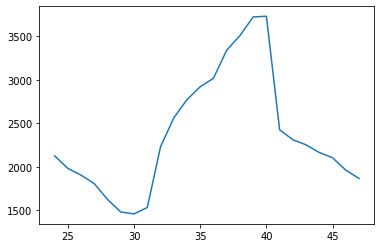

In [346]:
plt.plot(combined_df_processed[combined_df_processed>0])

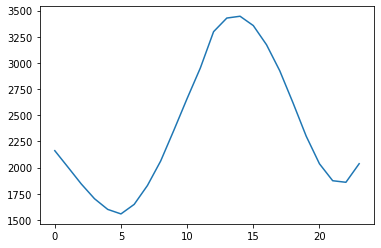

In [347]:
plt.plot(savgol_filter(combined_df_processed, 11, 3))

In [348]:
folder_path = working_path + "/dynamic_simulation_result"
file_prefix = "occupancy"

# Create a list to store the DataFrames
dfs = []

In [349]:
for file_name in glob.glob(os.path.join(folder_path, file_prefix + '*.csv')):
    # Read the csv file into a DataFrame
    df = pd.read_csv(file_name)

    # Append the DataFrame to the list
    dfs.append(df)

# Concatenate all data into one DataFrame
combined_occ = pd.concat(dfs, ignore_index=True)

In [350]:
combined_occ = combined_occ.reset_index(drop = True)

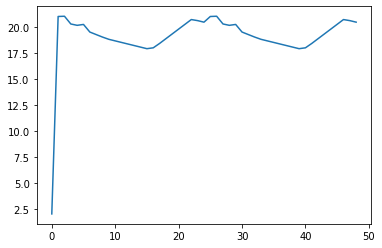

In [351]:
plt.plot(combined_occ['bldg_1_occupancy'])

In [352]:
all_combinted = pd.concat([combined_df, combined_occ], axis = 1)

In [353]:
all_combinted.to_csv('data/short_commute_all_results.csv', index = None)

In [354]:
# compare EV v.s. Non-EV

In [355]:
EV = pd.read_csv('data/EV_all_results.csv')

In [356]:
non_EV = pd.read_csv('data/non_EV_all_results.csv')

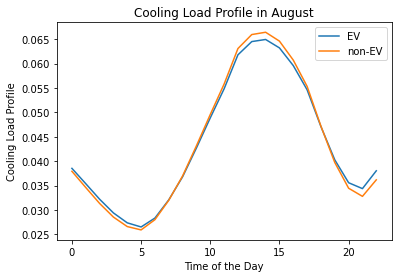

In [358]:
plt.title('Cooling Load Profile in August')
plt.plot(savgol_filter(EV['4'][24:47],11,3)/savgol_filter(EV['4'][24:47],3,1).sum())
plt.plot(savgol_filter(non_EV['4'][24:47],11,3)/savgol_filter(non_EV['4'][24:47],3,1).sum())
plt.legend(['EV','non-EV'])
plt.xlabel('Time of the Day')
plt.ylabel('Cooling Load Profile')
plt.show()

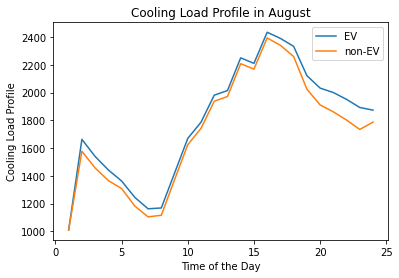

In [359]:
plt.title('Cooling Load Profile in August')
plt.plot(EV['4'][1:25])
plt.plot(non_EV['4'][1:25])
plt.legend(['EV','non-EV'])
plt.xlabel('Time of the Day')
plt.ylabel('Cooling Load Profile')
plt.show()

In [360]:
# compare long and short commute

In [367]:
long_commute = pd.read_csv('data/long_commute_all_results.csv')

In [368]:
short_commute = pd.read_csv('data/short_commute_all_results.csv')

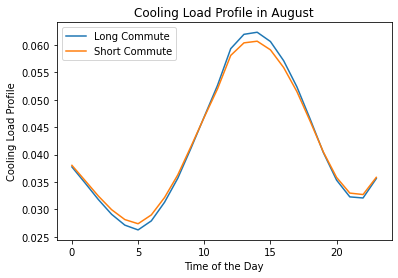

In [376]:
plt.title('Cooling Load Profile in August')
plt.plot(savgol_filter(long_commute['4'][24:48],11,3)/savgol_filter(long_commute['4'][24:48],3,1).sum())
plt.plot(savgol_filter(short_commute['4'][24:48],11,3)/savgol_filter(short_commute['4'][24:48],3,1).sum())
plt.legend(['Long Commute','Short Commute'])
plt.xlabel('Time of the Day')
plt.ylabel('Cooling Load Profile')
plt.show()

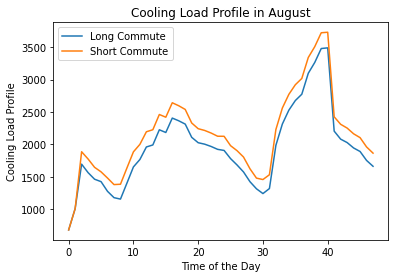

In [372]:
plt.title('Cooling Load Profile in August')
plt.plot(long_commute['4'])
plt.plot(short_commute['4'])
plt.legend(['Long Commute','Short Commute'])
plt.xlabel('Time of the Day')
plt.ylabel('Cooling Load Profile')
plt.show()